# Derivatives on the computer: symbolic differentiation and finite differences

Given a function $f$, we want $f'(x)$. We look at two ways to get it on a computer:

| approach | idea | result | Python |
|---|---|---|---|
| **symbolic** | apply the rules of calculus to a **formula** | a formula for $f'$, exact | `sympy.diff` |
| **finite differences** | evaluate $f$ at nearby points, take a **difference quotient** | a number, with an error | forward, backward, central, 5-point formulas |

We use the **same function** in both parts:
$$ f(x) = x^2 \sin x \; e^{-x/2}, \qquad x_0 = 1. $$

The first cell loads the packages. Run it first, then run the notebook from top to bottom: each part defines what it needs just before using it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

## Part A. Symbolic differentiation (SymPy)

SymPy works with **expressions**, not numbers. `sp.diff(f, x)` applies the product, quotient and chain rules and returns a new expression.

| task | call |
|---|---|
| declare a symbol | `x = sp.symbols("x")` |
| first, $n$-th derivative | `sp.diff(f, x)`, `sp.diff(f, x, n)` |
| simplify | `sp.simplify(expr)` |
| value at a point | `expr.subs(x, 1)`, then `float(...)` |
| turn into a NumPy function | `fp = sp.lambdify(x, expr, "numpy")` |

### Step 1: declare the symbol and the function

`x` is not a number but a **symbol**. Any formula built from it with SymPy functions (`sp.sin`, `sp.exp`, ...) is a SymPy **expression**.

In [2]:
x = sp.symbols("x")
f_sym = x**2 * sp.sin(x) * sp.exp(-x/2)
f_sym

x**2*exp(-x/2)*sin(x)

### Step 2: differentiate

In [3]:
df_sym  = sp.diff(f_sym, x)        # f'
d2f_sym = sp.diff(f_sym, x, 2)     # f''

print("f'  =", df_sym)
print("f'' =", sp.simplify(d2f_sym))
print()
print("f'(1) exact  :", df_sym.subs(x, 1))
print("f'(1) numeric:", float(df_sym.subs(x, 1)))

f'  = -x**2*exp(-x/2)*sin(x)/2 + x**2*exp(-x/2)*cos(x) + 2*x*exp(-x/2)*sin(x)
f'' = (-3*x**2*sin(x)/4 - x**2*cos(x) - 2*x*sin(x) + 4*x*cos(x) + 2*sin(x))*exp(-x/2)

f'(1) exact  : exp(-1/2)*cos(1) + 3*exp(-1/2)*sin(1)/2
f'(1) numeric: 1.093276841339319


To plot, or to evaluate at many points, turn the expressions into NumPy functions with `lambdify`.

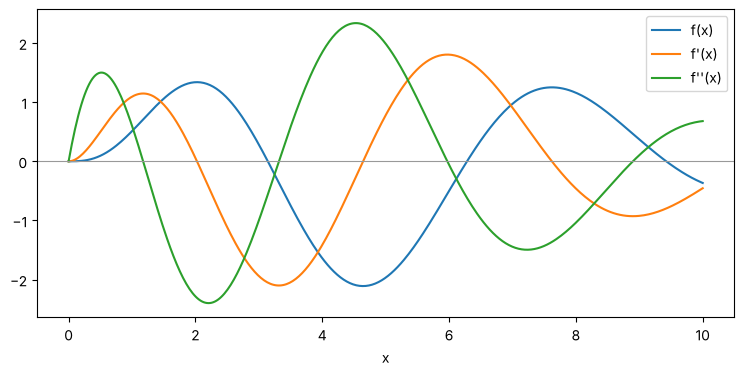

In [4]:
f_np   = sp.lambdify(x, f_sym,   "numpy")
df_np  = sp.lambdify(x, df_sym,  "numpy")
d2f_np = sp.lambdify(x, d2f_sym, "numpy")

xx = np.linspace(0, 10, 400)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(xx, f_np(xx),   label="f(x)")
ax.plot(xx, df_np(xx),  label="f'(x)")
ax.plot(xx, d2f_np(xx), label="f''(x)")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel("x"); ax.legend()
plt.show()

exact = float(df_sym.subs(x, 1))     # exact f'(1): the reference for Part B

- Symbolic differentiation gives an **exact formula**.
- It needs a **formula** for $f$.
- We use it below as the **exact reference** for the finite differences.

## Part B. Finite differences

Now we forget the formula and only **evaluate** $f$ at a few points. All formulas below come from Taylor's theorem:
$$ f(x \pm h) = f(x) \pm h f'(x) + \tfrac{h^2}{2} f''(x) \pm \tfrac{h^3}{6} f'''(x) + \dots $$

### Step 1: the function as a NumPy function

For finite differences we need a function that takes numbers (or NumPy arrays) and returns numbers. It is the same $f$, written with `np.sin` and `np.exp` instead of `sp.sin` and `sp.exp`.

In [5]:
def f(x):
    return x**2 * np.sin(x) * np.exp(-x/2)

print("f(1) =", f(1.0))

f(1) = 0.5103779515445728


### Step 2: forward difference

Keep the first two terms of $f(x+h) = f(x) + h f'(x) + \tfrac{h^2}{2} f''(x) + \dots$ and solve for $f'(x)$:
$$ f'(x) \approx \frac{f(x+h) - f(x)}{h}, \qquad \text{error} \approx \frac{h}{2} f''(x) = O(h). $$

Each formula is a function of `f`, the point `x` and the step `h`; we check it at $x = 1$ with $h = 0.1$.

In [6]:
def forward(f, x, h):
    return (f(x + h) - f(x)) / h

print("forward, h = 0.1:", forward(f, 1.0, 0.1), "   error:", abs(forward(f, 1.0, 0.1) - exact))

forward, h = 0.1: 1.117821685059659    error: 0.024544843720339937


### Step 3: backward difference

The same with $f(x-h) = f(x) - h f'(x) + \tfrac{h^2}{2} f''(x) - \dots$:
$$ f'(x) \approx \frac{f(x) - f(x-h)}{h}, \qquad \text{error} \approx -\frac{h}{2} f''(x) = O(h). $$

About the same size of error as forward, but with the **opposite sign**.

In [7]:
def backward(f, x, h):
    return (f(x) - f(x - h)) / h

print("backward, h = 0.1:", backward(f, 1.0, 0.1), "   error:", abs(backward(f, 1.0, 0.1) - exact))

backward, h = 0.1: 1.0580620704846455    error: 0.035214770854673505


### Step 4: central difference

Subtract the two Taylor series: the $f(x)$ and $f''$ terms cancel,
$$ f(x+h) - f(x-h) = 2h f'(x) + \tfrac{h^3}{3} f'''(x) + \dots $$
$$ f'(x) \approx \frac{f(x+h) - f(x-h)}{2h}, \qquad \text{error} \approx \frac{h^2}{6} f'''(x) = O(h^2). $$

It is the **average** of forward and backward: their errors cancel.

In [8]:
def central(f, x, h):
    return (f(x + h) - f(x - h)) / (2*h)

print("central, h = 0.1:", central(f, 1.0, 0.1), "   error:", abs(central(f, 1.0, 0.1) - exact))

central, h = 0.1: 1.0879418777721521    error: 0.005334963567166895


### Step 5: 5-point (fourth-order) central difference

Combine central differences with steps $h$ and $2h$ so that the $h^2$ error terms cancel too:
$$ f'(x) \approx \frac{-f(x+2h) + 8f(x+h) - 8f(x-h) + f(x-2h)}{12h}, \qquad \text{error} = O(h^4). $$

In [9]:
def five_point(f, x, h):
    return (-f(x + 2*h) + 8*f(x + h) - 8*f(x - h) + f(x - 2*h)) / (12*h)

print("5-point, h = 0.1:", five_point(f, 1.0, 0.1), "   error:", abs(five_point(f, 1.0, 0.1) - exact))

5-point, h = 0.1: 1.0932301850886785    error: 4.665625064048662e-05


### Step 6: summary, and a list to loop over

| name | formula | error |
|---|---|---|
| forward | $\dfrac{f(x+h) - f(x)}{h}$ | $O(h)$ |
| backward | $\dfrac{f(x) - f(x-h)}{h}$ | $O(h)$ |
| central | $\dfrac{f(x+h) - f(x-h)}{2h}$ | $O(h^2)$ |
| 5-point | $\dfrac{-f(x+2h) + 8f(x+h) - 8f(x-h) + f(x-2h)}{12h}$ | $O(h^4)$ |

$O(h^p)$ means: halve $h$ and the error is divided by $2^p$.

In Python a function is an object like any other, so we can put the four functions in a **list** and loop over them, with a second list holding their names.

In [10]:
fd_names   = ["forward", "backward", "central", "5-point"]
fd_methods = [forward, backward, central, five_point]

for name, D in zip(fd_names, fd_methods):
    print(f"{name:9s}  h = 0.1:  error = {abs(D(f, 1.0, 0.1) - exact):.2e}")

forward    h = 0.1:  error = 2.45e-02
backward   h = 0.1:  error = 3.52e-02
central    h = 0.1:  error = 5.33e-03
5-point    h = 0.1:  error = 4.67e-05


### Example 1: the error at $x_0 = 1$ for several step sizes

In [11]:
x0 = 1.0
print(f"exact f'(1) = {exact:.15f}\n")
print(f"{'h':>8s}" + "".join(f"{name:>12s}" for name in fd_names))
for h in [1e-1, 1e-2, 1e-3, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12]:
    print(f"{h:8.0e}" + "".join(f"{abs(D(f, x0, h) - exact):12.2e}" for D in fd_methods))

exact f'(1) = 1.093276841339319

       h     forward    backward     central     5-point
   1e-01    2.45e-02    3.52e-02    5.33e-03    4.67e-05
   1e-02    2.95e-03    3.06e-03    5.35e-05    4.68e-09
   1e-03    3.00e-04    3.01e-04    5.35e-07    5.76e-13
   1e-04    3.00e-05    3.00e-05    5.35e-09    2.29e-13
   1e-06    3.00e-07    3.00e-07    4.12e-12    1.44e-11
   1e-08    5.49e-09    5.61e-09    5.96e-11    1.91e-09
   1e-10    2.61e-07    2.61e-07    2.61e-07    4.46e-07
   1e-12    7.08e-05    4.02e-05    1.53e-05    3.38e-05


### Example 2: error against $h$ on a log-log plot

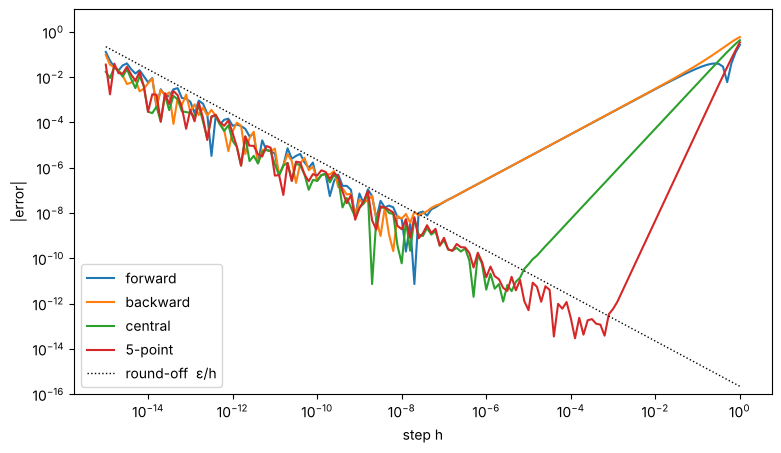

In [12]:
hs = np.logspace(-15, 0, 151)
fig, ax = plt.subplots(figsize=(9, 5))
for name, D in zip(fd_names, fd_methods):
    ax.loglog(hs, np.abs(D(f, x0, hs) - exact) + 1e-20, label=name)
ax.loglog(hs, 2.2e-16 / hs, "k:", lw=1, label="round-off  ε/h")
ax.set_xlabel("step h"); ax.set_ylabel("|error|")
ax.set_ylim(1e-16, 1e1); ax.legend()
plt.show()

- **Right side (large $h$): truncation error.** It falls with slope 1 (forward, backward), 2 (central) and 4 (5-point). Forward and backward are equally good; central and 5-point are much better.
- **Left side (small $h$): round-off error.** $f(x+h)$ and $f(x)$ are almost equal, so their difference loses digits; dividing by a tiny $h$ makes it worse. This error grows like $\varepsilon / h$, $\varepsilon \approx 2.2\times10^{-16}$.
- **Together:** as $h$ gets smaller, the error first goes **down** (less truncation error) and then goes **up** again (more round-off error). Each curve is V-shaped, so each formula has a **best step size** $h$ at the bottom of its V. Making $h$ smaller than that only makes the result worse.
- Read off from the plot above ($f$ at $x_0 = 1$):

| formula | best $h$ | best error |
|---|---|---|
| forward, backward | $\approx 10^{-8}$ | $\approx 10^{-8}$ |
| central | $\approx 10^{-5}$ | $\approx 10^{-11}$ |
| 5-point | $\approx 10^{-3}$ | $\approx 10^{-13}$ |

### Example 3: the derivative on a whole interval

The formulas work with NumPy arrays, so we can compute $f'$ at many points at once.

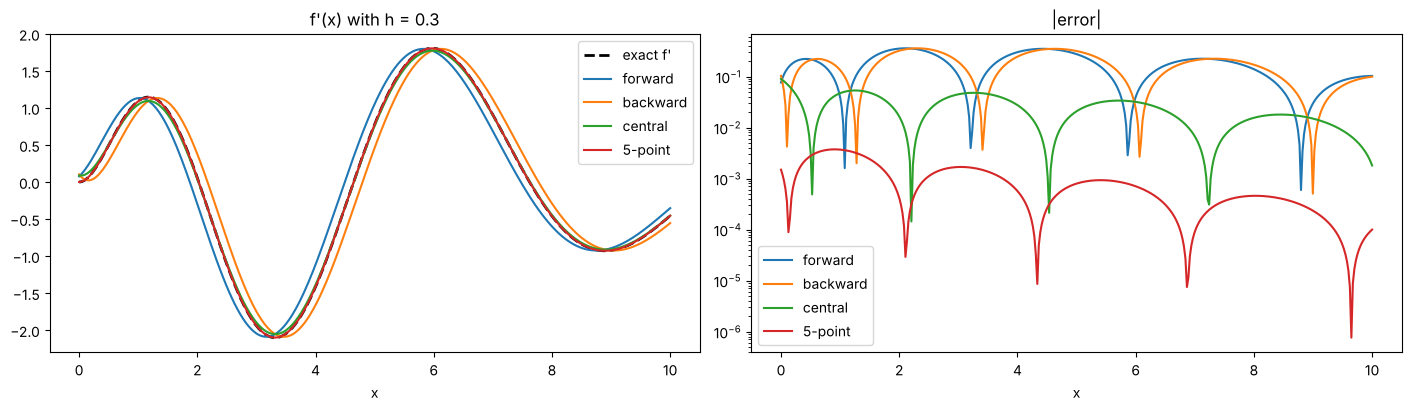

In [13]:
h = 0.3                                      # a large h, to make the differences visible
fig, axs = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
axs[0].plot(xx, df_np(xx), "k--", lw=2, label="exact f'")
for name, D in zip(fd_names, fd_methods):
    axs[0].plot(xx, D(f, xx, h), label=name)
    axs[1].semilogy(xx, np.abs(D(f, xx, h) - df_np(xx)) + 1e-20, label=name)
axs[0].set_title(f"f'(x) with h = {h}"); axs[0].legend()
axs[1].set_title("|error|"); axs[1].legend()
for ax in axs: ax.set_xlabel("x")
plt.show()

- With $h = 0.3$ forward and backward are visibly shifted (to opposite sides), central is close, 5-point is on top of the exact curve.
- Finite differences only need **values** of $f$, not a formula. But they are never exact, and you must choose $h$.

## Comparison at $x_0 = 1$

In [14]:
names  = ["symbolic (SymPy)", "forward,  h=1e-8", "backward, h=1e-8", "central,  h=1e-5",
          "5-point,  h=1e-3"]
values = [exact, forward(f, 1.0, 1e-8), backward(f, 1.0, 1e-8), central(f, 1.0, 1e-5),
          five_point(f, 1.0, 1e-3)]

print(f"{'method':18s} {'derivative':>20s} {'error':>10s}")
for name, v in zip(names, values):
    print(f"{name:18s} {v:20.15f} {abs(v - exact):10.1e}")

method                       derivative      error
symbolic (SymPy)      1.093276841339319    0.0e+00
forward,  h=1e-8      1.093276846830804    5.5e-09
backward, h=1e-8      1.093276835728574    5.6e-09
central,  h=1e-5      1.093276841285240    5.4e-11
5-point,  h=1e-3      1.093276841338743    5.8e-13


| | symbolic (SymPy) | finite differences |
|---|---|---|
| needs | a formula | values of $f$ |
| result | exact formula | approximate number |
| choose a step $h$? | no | **yes**: too large = truncation error, too small = round-off |

- Use a **central difference** to check a derivative you computed in another way (by hand or with SymPy).

## Exercises

In each exercise use **both** approaches. Write each function twice (a SymPy expression and a NumPy function), as in Parts A and B.

**Syntax**

| task | call |
|---|---|
| symbol, derivative, $n$-th derivative | `x = sp.symbols("x")`, `sp.diff(f, x)`, `sp.diff(f, x, n)` |
| zero of an expression near a guess | `sp.nsolve(expr, x, x0)` |
| expression $\to$ NumPy function | `sp.lambdify(x, expr, "numpy")` |
| finite differences | `forward(f, x, h)`, `backward(f, x, h)`, `central(f, x, h)`, `five_point(f, x, h)` |
| $\ln u$ | SymPy: `sp.log(u)`; NumPy: `np.log(u)` |
| $\sqrt{u}$ | SymPy: `sp.sqrt(u)`; NumPy: `np.sqrt(u)` |
| $\cos u$ | SymPy: `sp.cos(u)`; NumPy: `np.cos(u)` |
| log-log plot | `ax.loglog(h, err)`; values `np.logspace(a, b, n)` |

**Exercise 1.** Let
$$ f(x) = \frac{\ln(1 + x^2)}{1 + x}. $$

(a) **Symbolic.** Compute $f'$ and $f''$ with SymPy. Plot $f$ and $f'$ on $[0, 5]$ (use `lambdify`). Find the maximum of $f$ on $[0, 5]$ by solving $f'(x) = 0$ with `sp.nsolve` (start from a guess read off the plot), and check that $f'' < 0$ there.

(b) **Finite differences.** At $x = 1$, compute the forward, backward, central and 5-point approximations of $f'(1)$ for $h = 10^{-1}, 10^{-2}, \dots, 10^{-15}$. Plot the four errors against $h$ on a log-log plot (use the exact value from (a)). Read off the best $h$ and the smallest error for each formula.

In [15]:
# Exercise 1

**Exercise 2.** Let
$$ f(x) = \sqrt{1 + x^2}\,\cos(3x) \quad \text{on } [-2, 2]. $$

(a) **Symbolic.** Compute $f'$ with SymPy and turn it into a NumPy function with `lambdify`.

(b) **Finite differences.** On 200 points of $[-2, 2]$ compute $f'$ with the four formulas, once with $h = 0.1$ and once with $h = 10^{-3}$. Plot the errors against $x$ (log scale on the $y$-axis), using (a) as the exact derivative. Which formula is best, and by how much does each error drop when $h$ goes from $0.1$ to $10^{-3}$? Does this agree with the orders $O(h)$, $O(h^2)$, $O(h^4)$?

(c) **Best step size.** At $x = 0.5$, compute the error of the central and the 5-point formulas for $h = 10^{-1}, 10^{-2}, \dots, 10^{-15}$ and plot both against $h$ on a log-log plot. Read off the best $h$ and the smallest error for each, and compare with the table in Part B.

In [16]:
# Exercise 2